# Has the rise of streaming services caused a decrease in box office revenue?

As streaming services have become mroe prevelant, there has been an increase in the number of films that are not released in cinemas before public release. This has been highlighted by many directors and actors, especially Chris Nolan who released The Odyssey this year after filming the entire project using IMAX cameras to try and encourage consumers back into the cinema.

I am therefore investigating whether there seems to be any correlation and causation between the rise of streaming services and a drop in box office revenue.

I have acquired 3 datasets from kaggle for use in this project, one which has the box office revenue of all films released between 2000 and 2024, and another two which contain the number of subscribers for both Hulu and Netflix between 2011 and 2020.

In this notebook I will perform any data cleaning and EDA before using the cleaned data in a R notebook for the causal analysis.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt

In [2]:
hulu_subs = pd.read_csv('HuluNumSubscribers.csv')
netflix_subs = pd.read_csv('NetflixNumSubscribers.csv')
box_office_data = pd.read_csv('enhanced_box_office_data(2000-2024)u.csv')
release_dates = pd.read_csv('Movie Dataset.csv')

In [3]:
streaming_subs = netflix_subs.merge(hulu_subs, how = 'left', on = 'Year')
streaming_subs = streaming_subs.rename(columns = {'Subscribers_x': 'Netflix_subs_(M)','Subscribers_y': 'Hulu_subs_(M)'}) 
streaming_subs['Total_subs_(M)'] = (streaming_subs['Netflix_subs_(M)'] + streaming_subs['Hulu_subs_(M)'])
print(streaming_subs)

   Year  Netflix_subs_(M)  Hulu_subs_(M)  Total_subs_(M)
0  2011              21.5              1            22.5
1  2012              25.7              2            27.7
2  2013              35.6              4            39.6
3  2014              47.9              6            53.9
4  2015              62.7             10            72.7
5  2016              79.9             12            91.9
6  2017              99.0             17           116.0
7  2018             124.3             25           149.3
8  2019             151.5             28           179.5
9  2020             192.9             39           231.9


Text(0, 0.5, 'Subscribers (M)')

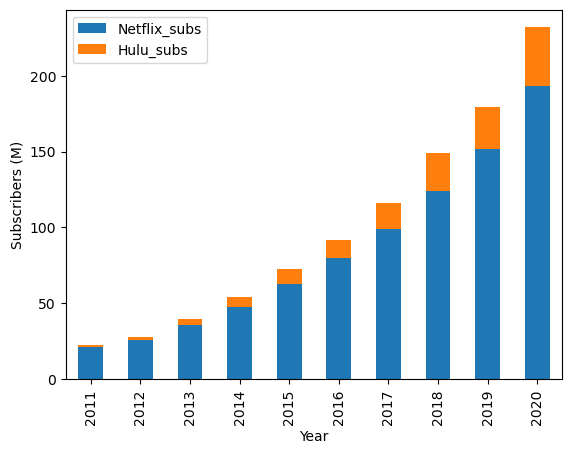

In [4]:
Total_subs_plot = streaming_subs.plot(x='Year', y=['Netflix_subs_(M)', 'Hulu_subs_(M)'], kind = 'bar', stacked = True)
Total_subs_plot.legend(['Netflix_subs','Hulu_subs'])
Total_subs_plot.set_ylabel('Subscribers (M)')

This bar chart shows that since starting to offer streaming services the number of subscribers across both hulu and netflix has increased from around 25m to 250m. It is to be assumed that all other streaming services have a similar trend from when they first started. I chose to use Hulu and Netflix as they both started in 2011 and this is seemingly the beginning of streaming services taking off.

In [5]:
streaming_subs.to_csv("cleaned_streaming.csv", index = False)

In [6]:
release_dates.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [7]:
release_dates['Release_Date'] = pd.to_datetime(release_dates['Release_Date'], errors = 'coerce')
release_dates = release_dates[release_dates['Release_Date'] > '1999-12-31']
release_dates.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [8]:

box_office_data.head()

,Rank,Release Group,$Worldwide,$Domestic,Domestic %,$Foreign,Foreign %,Year,Genres,Rating,Vote_Count,Original_Language,Production_Countries
0,1,Mission: Impossible II,546388108.0,215409889.0,39.4,330978219.0,60.6,2000,"Adventure, Action, Thriller",6.126/10,6741.0,en,United States of America
1,2,Gladiator,460583960.0,187705427.0,40.8,272878533.0,59.2,2000,"Action, Drama, Adventure",8.217/10,19032.0,en,"United Kingdom, United States of America"
2,3,Cast Away,429632142.0,233632142.0,54.4,196000000.0,45.6,2000,"Adventure, Drama",7.663/10,11403.0,en,United States of America
3,4,What Women Want,374111707.0,182811707.0,48.9,191300000.0,51.1,2000,"Comedy, Romance",6.45/10,3944.0,en,"United Kingdom, United States of America"
4,5,Dinosaur,349822765.0,137748063.0,39.4,212074702.0,60.6,2000,"Animation, Family, Adventure",6.544/10,2530.0,en,United States of America


In [9]:
box_office_release_dates = box_office_data.merge(release_dates, left_on = 'Release Group', right_on = 'Title', how = 'left')
box_office_release_dates.info()

<class 'pandas.DataFrame'>
RangeIndex: 5095 entries, 0 to 5094
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Rank                  5095 non-null   int64         
 1   Release Group         5095 non-null   str           
 2   $Worldwide            5095 non-null   float64       
 3   $Domestic             5095 non-null   float64       
 4   Domestic %            5095 non-null   float64       
 5   $Foreign              5095 non-null   float64       
 6   Foreign %             5095 non-null   float64       
 7   Year                  5095 non-null   int64         
 8   Genres                4917 non-null   str           
 9   Rating                4925 non-null   str           
 10  Vote_Count_x          4925 non-null   float64       
 11  Original_Language_x   4925 non-null   str           
 12  Production_Countries  4895 non-null   str           
 13  Release_Date          2906 no

In [10]:
box_office_release_dates = box_office_release_dates.drop(columns = ['Year','Rating','Vote_Count_x','Original_Language_x','Production_Countries','Release Group','Overview','Vote_Count_y','Vote_Average','Original_Language_y','Genre','Poster_Url'])
box_office_release_dates = box_office_release_dates.dropna()
box_office_release_dates.info()

<class 'pandas.DataFrame'>
Index: 2885 entries, 0 to 5033
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Rank          2885 non-null   int64         
 1   $Worldwide    2885 non-null   float64       
 2   $Domestic     2885 non-null   float64       
 3   Domestic %    2885 non-null   float64       
 4   $Foreign      2885 non-null   float64       
 5   Foreign %     2885 non-null   float64       
 6   Genres        2885 non-null   str           
 7   Release_Date  2885 non-null   datetime64[us]
 8   Title         2885 non-null   str           
 9   Popularity    2885 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1), str(2)
memory usage: 247.9 KB


In [11]:
unique_genres = box_office_release_dates['Genres'].str.split(', ').explode().unique()
print(unique_genres)


<StringArray>
[      'Adventure',          'Action',        'Thriller',           'Drama',
          'Comedy',         'Romance',       'Animation',          'Family',
         'Fantasy',          'Horror',         'Mystery',           'Crime',
         'History',             'War', 'Science Fiction',           'Music',
         'Western',     'Documentary',        'TV Movie']
Length: 19, dtype: str


In [12]:
for x in unique_genres:
    condition = box_office_release_dates['Genres'].str.contains(x, case=False, na=False)
    box_office_release_dates[x] = np.where(condition, box_office_release_dates['$Worldwide'], 0)
box_office_release_dates.head()

,Rank,$Worldwide,$Domestic,Domestic %,$Foreign,Foreign %,Genres,Release_Date,Title,Popularity,...,Horror,Mystery,Crime,History,War,Science Fiction,Music,Western,Documentary,TV Movie
0,1,546388108.0,215409889.0,39.4,330978219.0,60.6,"Adventure, Action, Thriller",2000-05-24,Mission: Impossible II,39.663,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,460583960.0,187705427.0,40.8,272878533.0,59.2,"Action, Drama, Adventure",2000-05-01,Gladiator,58.099,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,429632142.0,233632142.0,54.4,196000000.0,45.6,"Adventure, Drama",2000-12-22,Cast Away,43.596,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,374111707.0,182811707.0,48.9,191300000.0,51.1,"Comedy, Romance",2000-12-15,What Women Want,30.686,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,349822765.0,137748063.0,39.4,212074702.0,60.6,"Animation, Family, Adventure",2000-05-19,Dinosaur,85.838,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
box_office_genres = box_office_release_dates.drop(columns = ['$Worldwide','$Domestic','Domestic %','$Foreign','Foreign %','Genres'])

In [14]:
long_box_office = pd.melt(box_office_genres, id_vars=['Title', 'Release_Date'], value_vars = unique_genres)
long_box_office.rename(columns={ "variable" : "Genre", 'value':'Worldwide Revenue ($)'}, inplace = True)
long_box_office= long_box_office[long_box_office['Worldwide Revenue ($)'] != 0]
print(long_box_office.info())
print(long_box_office.head())

<class 'pandas.DataFrame'>
Index: 8075 entries, 0 to 54784
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Title                  8075 non-null   str           
 1   Release_Date           8075 non-null   datetime64[us]
 2   Genre                  8075 non-null   str           
 3   Worldwide Revenue ($)  8075 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 315.4 KB
None
                    Title Release_Date      Genre  Worldwide Revenue ($)
0  Mission: Impossible II   2000-05-24  Adventure            546388108.0
1               Gladiator   2000-05-01  Adventure            460583960.0
2               Cast Away   2000-12-22  Adventure            429632142.0
4                Dinosaur   2000-05-19  Adventure            349822765.0
7       The Perfect Storm   2000-06-29  Adventure            328718434.0


<Axes: xlabel='Release_Date', ylabel='$Worldwide'>

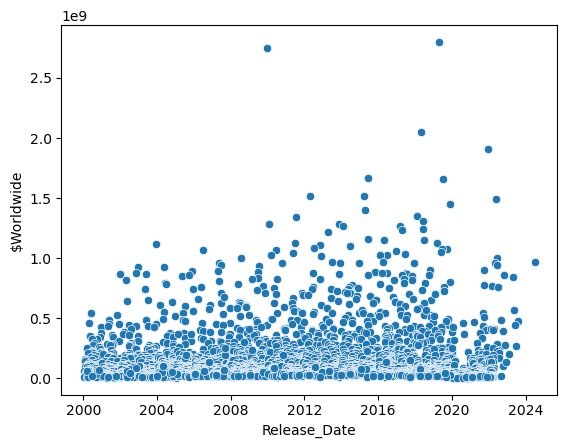

In [15]:
box_office_release_dates = box_office_release_dates[box_office_release_dates['TV Movie'] == 0]
sns.scatterplot(data=box_office_release_dates, x='Release_Date', y='$Worldwide')

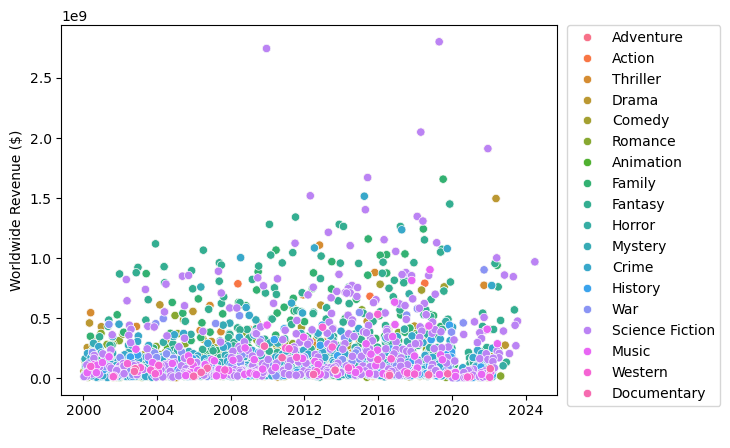

In [16]:
long_box_office_cinema = long_box_office[long_box_office['Genre'] != 'TV Movie']

sns.scatterplot(data=long_box_office_cinema, x='Release_Date', y='Worldwide Revenue ($)', hue = 'Genre')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

There seems to be a large drop off in box office revenue in 2020. This is likely due to the Covid-19 pandemic, below I will plot just the data up until 2020. However I will use all the data for the causal analysis as I will use a bandwidth that will mean only data around my cutoff point will be relevant to the analysis

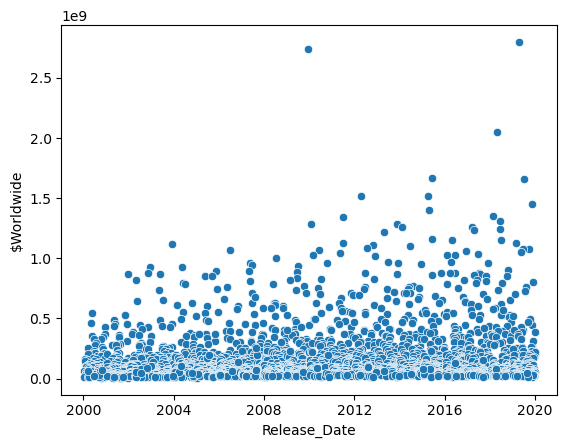

In [17]:
box_office_2019 = box_office_release_dates[box_office_release_dates['Release_Date'] < '2020-01-01']

total_plot = sns.scatterplot(data=box_office_2019, x='Release_Date', y='$Worldwide')

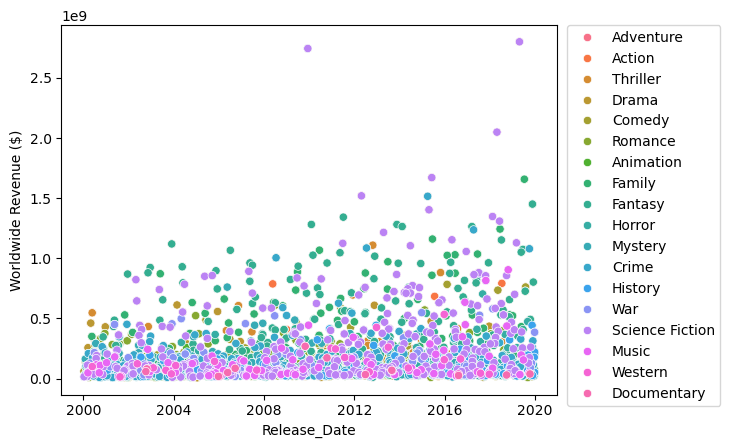

In [18]:
box_office_2019_genres = long_box_office_cinema[long_box_office_cinema['Release_Date'] < '2020-01-01']

genre_plot = sns.scatterplot(data=box_office_2019_genres, x='Release_Date', y='Worldwide Revenue ($)', hue = 'Genre')
genre_plot.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

In [19]:
cleaned_box_office = box_office_2019.drop(columns = unique_genres)
cleaned_box_office.head()

,Rank,$Worldwide,$Domestic,Domestic %,$Foreign,Foreign %,Genres,Release_Date,Title,Popularity
0,1,546388108.0,215409889.0,39.4,330978219.0,60.6,"Adventure, Action, Thriller",2000-05-24,Mission: Impossible II,39.663
1,2,460583960.0,187705427.0,40.8,272878533.0,59.2,"Action, Drama, Adventure",2000-05-01,Gladiator,58.099
2,3,429632142.0,233632142.0,54.4,196000000.0,45.6,"Adventure, Drama",2000-12-22,Cast Away,43.596
3,4,374111707.0,182811707.0,48.9,191300000.0,51.1,"Comedy, Romance",2000-12-15,What Women Want,30.686
4,5,349822765.0,137748063.0,39.4,212074702.0,60.6,"Animation, Family, Adventure",2000-05-19,Dinosaur,85.838


In [20]:
box_office_release_dates.to_csv('cleaned_box_office_2024.csv', index = False)
cleaned_box_office.to_csv('cleaned_box_office_2020.csv', index = False)